Project Title & Domain

Project Title: Accounts Receivable Analysis

Domain: Accounting & Finance — Accounts Receivable

Project Overview

This project focuses on analyzing accounts receivable records to understand recorded payment delays, invoice ageing, customer payment patterns, payment terms, and clearing activity. The intended outcome is to identify patterns that may help Accounts Receivable teams prioritize collection follow-ups and monitor receivables more effectively.

Business Problem

Accounts Receivable teams need reliable information about invoice due dates, recorded delays, customers, and settlement activity to monitor outstanding receivables. This project will inspect the available dataset and prepare it for later analysis of payment-delay and collection patterns.

Project Objectives

Summarize invoice records and available ageing or delay categories.
Examine recorded payment-delay patterns by customer and region, where the fields support the analysis.
Compare delay patterns across payment terms and amount categories.
Inspect document, due, and clearing dates where available and valid.
Identify data-quality issues that may affect later analysis.

Dataset Description

Working dataset: Account receivable analysis data set.csv
Format: CSV
Expected size from prior inspection: approximately 45,839 rows and 29 columns; this will be confirmed below.
Original source URL: https://www.kaggle.com/datasets/sonalisingh1411/accounts-receivable-and-payment-delay-analysis?select=Dataset.csv
Important limitation: Currency, row granularity, and the meanings of financial and derived fields must be confirmed before interpreting results.

Planned Analysis

After the dataset source, field definitions, and data quality have been reviewed, the later phases may include:

Initial data-quality review: Check missing values, exact duplicate rows, data types, and distinct values.

Invoice amount analysis: Summarize the recorded amount and compare the provided amount bands.

Delay analysis: Summarize recorded delay values and categories, after validating the meaning of the delay field.

Payment-term analysis: Compare delay patterns across payment-term groups.

Date-based analysis: Inspect document, due, posting, and clearing dates and explore trends over time where appropriate.

Customer-level analysis: Identify customer-level patterns using suitable aggregation and privacy-conscious reporting.

Visualization: Create appropriate charts and summary tables for the final report or dashboard. The analysis will not label an invoice as currently outstanding solely from a missing clearing date until the dataset's recording rules and status logic have been confirmed.

Scope and Limitations

Project Scope

Phase 1 focuses on the proposal, loading the working CSV, and initial inspection. It includes reviewing dataset dimensions, data types, missing values, exact duplicate rows, distinct values, and the availability of relevant accounts receivable fields.

Detailed cleaning, exploratory data analysis, and final visualizations will be completed in later phases.

Project Limitations

Currency and amount meaning: The currency, units, and whether Amount represents invoice value, balance, or another measure are not confirmed.

Field definitions: The calculation of Days_Overdue_Delay, DelayFlag, and the provided bins must be validated.

Historical coverage: The period represented by the file must be established from the actual dates. 54 Repeated records: A customer or document may appear more than once for valid business reasons; exact duplicates and repeated identifiers must be assessed separately.

Association is not causation: Any relationship found between payment terms, customer characteristics, and delays will not by itself establish cause.

Confidentiality: Customer names and identifiers should be masked or aggregated in public notebooks and reports where appropriate.

1. Import Required Libraries
We use Pandas for loading and inspecting the dataset, and NumPy for general numerical operations. Visualization libraries can be added in later phases when EDA and charts are required.

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [2]:
file_path = Path("Account receivable analysis data set.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Place the CSV at 'Account receivable analysis data set.csv' "
        "inside the project folder, or update file_path to match your folder structure."
    )

df = pd.read_csv("Account receivable analysis data set.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


In [3]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
df.head()

Number of rows: 45839
Number of columns: 29


,Cust_Num,Payment_Method_description,Document_No,Amount,Amount_Bins,Clearing_doc,Zipcode,Region,City,Customer_Name,Age_Of_Customer_Months,Age_Of_Customer_Year,Customer_Age_Year_Bins,Payment_Term,Payment_Term_Bins,Days_Overdue_Delay,Delay_Bins,Doc_Date,Net_Due_Date,Posting_Date,Clearing_date,No_of_orders_by_customer,Rank_of_order_by_customer,Weekday_clearing,Weekday_due,Quarter_clearing,DelayFlag,Weekday_clearnum,Weekday_due.1
0,5039221069,No Payment Method,91225035903,659903,200K+,80992136278,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,18,1 to 30,11/18/2014,2/28/2015,11/18/2014,3/18/2015,20,1,Wed,Sat,1,1,4,7
1,5039221069,No Payment Method,91225035904,16906,0 to 50K,80992136278,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,18,1 to 30,11/18/2014,2/28/2015,11/18/2014,3/18/2015,20,2,Wed,Sat,1,1,4,7
2,5039221069,No Payment Method,91225034522,24736,0 to 50K,80992134897,AX0034,AA126,AA66,AA64,155.0,12.0,10+,94,61 to 180,9,1 to 30,11/26/2014,2/28/2015,11/26/2014,03-09-2015,20,3,Mon,Sat,1,1,2,7
3,5039221069,No Payment Method,91225038274,17982,0 to 50K,80992138649,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,7,1 to 30,12/19/2014,3/31/2015,12/19/2014,04-07-2015,20,4,Tue,Tue,2,1,3,3
4,5039221069,No Payment Method,91225038275,86575,50K to 100K,80992138649,AX0034,AA126,AA66,AA64,155.0,12.0,10+,99,61 to 180,7,1 to 30,12/22/2014,3/31/2015,12/22/2014,04-07-2015,20,5,Tue,Tue,2,1,3,3


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45839 entries, 0 to 45838
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Cust_Num                    45839 non-null  int64  
 1   Payment_Method_description  45839 non-null  str    
 2   Document_No                 45839 non-null  int64  
 3   Amount                      45839 non-null  int64  
 4   Amount_Bins                 45839 non-null  str    
 5   Clearing_doc                45839 non-null  int64  
 6   Zipcode                     45839 non-null  str    
 7   Region                      45839 non-null  str    
 8   City                        45839 non-null  str    
 9   Customer_Name               45839 non-null  str    
 10  Age_Of_Customer_Months      45839 non-null  float64
 11  Age_Of_Customer_Year        45839 non-null  float64
 12  Customer_Age_Year_Bins      45839 non-null  str    
 13  Payment_Term                45839 non-null

In [5]:
display(df.dtypes.rename("data_type").to_frame())

,data_type
Cust_Num,int64
Payment_Method_description,str
Document_No,int64
Amount,int64
Amount_Bins,str
Clearing_doc,int64
Zipcode,str
Region,str
City,str
Customer_Name,str


In [6]:
df.shape

(45839, 29)

In [7]:
df.dtypes

Cust_Num                        int64
Payment_Method_description        str
Document_No                     int64
Amount                          int64
Amount_Bins                       str
Clearing_doc                    int64
Zipcode                           str
Region                            str
City                              str
Customer_Name                     str
Age_Of_Customer_Months        float64
Age_Of_Customer_Year          float64
Customer_Age_Year_Bins            str
Payment_Term                    int64
Payment_Term_Bins                 str
Days_Overdue_Delay              int64
Delay_Bins                        str
Doc_Date                          str
Net_Due_Date                      str
Posting_Date                      str
Clearing_date                     str
No_of_orders_by_customer        int64
Rank_of_order_by_customer       int64
Weekday_clearing                  str
Weekday_due                       str
Quarter_clearing                int64
DelayFlag   

In [8]:
df.size

1329331

Initial Description The dataset contains 45,839 rows and 29 columns, including customer information, invoice amounts, payment terms, overdue delays, and document and clearing dates. It includes numerical, categorical, and date-related columns. Some columns may contain missing values, and date fields may require conversion to appropriate data types. Initial data inspection will help identify missing values, duplicate records, and inconsistent data types that may need to be addressed during data cleaning.

## Creating a copy of data set

In [10]:
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (45839, 29)
Working dataset shape: (45839, 29)


## Check and handle missing values

# Checking duplicate values

In [11]:
duplicate_count = df_clean.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


## Checking missing values

In [12]:
 df_clean.isnull().sum()

Cust_Num                      0
Payment_Method_description    0
Document_No                   0
Amount                        0
Amount_Bins                   0
Clearing_doc                  0
Zipcode                       0
Region                        0
City                          0
Customer_Name                 0
Age_Of_Customer_Months        0
Age_Of_Customer_Year          0
Customer_Age_Year_Bins        0
Payment_Term                  0
Payment_Term_Bins             0
Days_Overdue_Delay            0
Delay_Bins                    0
Doc_Date                      0
Net_Due_Date                  0
Posting_Date                  0
Clearing_date                 0
No_of_orders_by_customer      0
Rank_of_order_by_customer     0
Weekday_clearing              0
Weekday_due                   0
Quarter_clearing              0
DelayFlag                     0
Weekday_clearnum              0
Weekday_due.1                 0
dtype: int64

## Standardizing column names

In [13]:
df_clean.columns = (
    df_clean.columns
      .str.strip()
      .str.lower()
      .str.replace(" ", "_", regex=False)
      .str.replace(".", "_", regex=False)
      .str.capitalize()
)

display(pd.Series(df_clean.columns, name="Standardized_Column_Names").to_frame())

,Standardized_Column_Names
0,Cust_num
1,Payment_method_description
2,Document_no
3,Amount
4,Amount_bins
5,Clearing_doc
6,Zipcode
7,Region
8,City
9,Customer_name


## Convert date columns

In [14]:
date_columns = [
    "Doc_date",
    "Net_due_date",
    "Posting_date",
    "Clearing_date"
]

for col in date_columns:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format="mixed",
        errors="coerce"
    )

date_validation = pd.DataFrame({
    "Data_type": df_clean[date_columns].dtypes.astype(str),
    "Invalid_or_missing_after_parse": df_clean[date_columns].isna().sum(),
    "Minimum_date": df_clean[date_columns].min(),
    "Maximum_date": df_clean[date_columns].max()
})

display(date_validation)

,Data_type,Invalid_or_missing_after_parse,Minimum_date,Maximum_date
Doc_date,datetime64[us],0,2011-11-23,2016-02-25
Net_due_date,datetime64[us],0,2012-05-21,2016-04-03
Posting_date,datetime64[us],0,2011-11-23,2016-02-25
Clearing_date,datetime64[us],0,2015-03-02,2016-03-17


## Clean text columns

In [15]:
text_columns = df_clean.select_dtypes(include=["object", "str"]).columns
for col in text_columns:
    df_clean[col] =df_clean[col].str.strip()
print("Text columns cleaned successfully!")
df_clean[text_columns].head()

Text columns cleaned successfully!


,Payment_method_description,Amount_bins,Zipcode,Region,City,Customer_name,Customer_age_year_bins,Payment_term_bins,Delay_bins,Weekday_clearing,Weekday_due
0,No Payment Method,200K+,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Wed,Sat
1,No Payment Method,0 to 50K,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Wed,Sat
2,No Payment Method,0 to 50K,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Mon,Sat
3,No Payment Method,0 to 50K,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Tue,Tue
4,No Payment Method,50K to 100K,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Tue,Tue


## DATA CLEANING AND PREPROCESSING

## Objective
The objective of this phase is to clean, organise and prepare the Accounts Receivable dataset for further analysis. 
This involves checking data quality, handling inconsistencies, standardising column names, converting date formats, creating new payment-related features, and generating customer-level payment summaries.

In [16]:
import numpy as np
import pandas as pd
from pathlib import Path
file_path = Path("Account receivable analysis data set.csv")

if not file_path.exists():
    raise FileNotFoundError(
        "Dataset not found. Place the CSV at 'Account receivable analysis data set.csv' "
        "inside the project folder, or update file_path to match your folder structure."
    )

df = pd.read_csv("Account receivable analysis data set.csv")
print("Dataset loaded successfully.")

Dataset loaded successfully.


## Creating a copy of data set

In [17]:
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Original dataset shape: (45839, 29)
Working dataset shape: (45839, 29)


In [18]:
print("Dataset shape:", df_clean.shape)
display(df_clean.head())

df_clean.info()

Dataset shape: (45839, 29)


,Cust_Num,Payment_Method_description,Document_No,Amount,Amount_Bins,Clearing_doc,Zipcode,Region,City,Customer_Name,Age_Of_Customer_Months,Age_Of_Customer_Year,Customer_Age_Year_Bins,Payment_Term,Payment_Term_Bins,Days_Overdue_Delay,Delay_Bins,Doc_Date,Net_Due_Date,Posting_Date,Clearing_date,No_of_orders_by_customer,Rank_of_order_by_customer,Weekday_clearing,Weekday_due,Quarter_clearing,DelayFlag,Weekday_clearnum,Weekday_due.1
0,5039221069,No Payment Method,91225035903,659903,200K+,80992136278,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,18,1 to 30,11/18/2014,2/28/2015,11/18/2014,3/18/2015,20,1,Wed,Sat,1,1,4,7
1,5039221069,No Payment Method,91225035904,16906,0 to 50K,80992136278,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,18,1 to 30,11/18/2014,2/28/2015,11/18/2014,3/18/2015,20,2,Wed,Sat,1,1,4,7
2,5039221069,No Payment Method,91225034522,24736,0 to 50K,80992134897,AX0034,AA126,AA66,AA64,155.0,12.0,10+,94,61 to 180,9,1 to 30,11/26/2014,2/28/2015,11/26/2014,03-09-2015,20,3,Mon,Sat,1,1,2,7
3,5039221069,No Payment Method,91225038274,17982,0 to 50K,80992138649,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,7,1 to 30,12/19/2014,3/31/2015,12/19/2014,04-07-2015,20,4,Tue,Tue,2,1,3,3
4,5039221069,No Payment Method,91225038275,86575,50K to 100K,80992138649,AX0034,AA126,AA66,AA64,155.0,12.0,10+,99,61 to 180,7,1 to 30,12/22/2014,3/31/2015,12/22/2014,04-07-2015,20,5,Tue,Tue,2,1,3,3


<class 'pandas.DataFrame'>
RangeIndex: 45839 entries, 0 to 45838
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Cust_Num                    45839 non-null  int64  
 1   Payment_Method_description  45839 non-null  str    
 2   Document_No                 45839 non-null  int64  
 3   Amount                      45839 non-null  int64  
 4   Amount_Bins                 45839 non-null  str    
 5   Clearing_doc                45839 non-null  int64  
 6   Zipcode                     45839 non-null  str    
 7   Region                      45839 non-null  str    
 8   City                        45839 non-null  str    
 9   Customer_Name               45839 non-null  str    
 10  Age_Of_Customer_Months      45839 non-null  float64
 11  Age_Of_Customer_Year        45839 non-null  float64
 12  Customer_Age_Year_Bins      45839 non-null  str    
 13  Payment_Term                45839 non-null

## Check and handle missing values

## Checking duplicate values

In [19]:
duplicate_count = df_clean.duplicated().sum()

print("Duplicate records:", duplicate_count)

Duplicate records: 0


## Checking missing values

In [20]:
# Check missing values in each column
missing_values = df_clean.isnull().sum()

print("Missing values in each column:")
display(missing_values)

# Calculate total missing values
print("Total Missing Values:",
      missing_values.sum())

# Check percentage of missing values
missing_percentage = (
    df_clean.isnull().mean() * 100
).round(2)

print("\nMissing Value Percentage:")
display(missing_percentage)

Missing values in each column:


Cust_Num                      0
Payment_Method_description    0
Document_No                   0
Amount                        0
Amount_Bins                   0
Clearing_doc                  0
Zipcode                       0
Region                        0
City                          0
Customer_Name                 0
Age_Of_Customer_Months        0
Age_Of_Customer_Year          0
Customer_Age_Year_Bins        0
Payment_Term                  0
Payment_Term_Bins             0
Days_Overdue_Delay            0
Delay_Bins                    0
Doc_Date                      0
Net_Due_Date                  0
Posting_Date                  0
Clearing_date                 0
No_of_orders_by_customer      0
Rank_of_order_by_customer     0
Weekday_clearing              0
Weekday_due                   0
Quarter_clearing              0
DelayFlag                     0
Weekday_clearnum              0
Weekday_due.1                 0
dtype: int64

Total Missing Values: 0

Missing Value Percentage:


Cust_Num                      0.0
Payment_Method_description    0.0
Document_No                   0.0
Amount                        0.0
Amount_Bins                   0.0
Clearing_doc                  0.0
Zipcode                       0.0
Region                        0.0
City                          0.0
Customer_Name                 0.0
Age_Of_Customer_Months        0.0
Age_Of_Customer_Year          0.0
Customer_Age_Year_Bins        0.0
Payment_Term                  0.0
Payment_Term_Bins             0.0
Days_Overdue_Delay            0.0
Delay_Bins                    0.0
Doc_Date                      0.0
Net_Due_Date                  0.0
Posting_Date                  0.0
Clearing_date                 0.0
No_of_orders_by_customer      0.0
Rank_of_order_by_customer     0.0
Weekday_clearing              0.0
Weekday_due                   0.0
Quarter_clearing              0.0
DelayFlag                     0.0
Weekday_clearnum              0.0
Weekday_due.1                 0.0
dtype: float64

In [21]:
# Identify blank values in text columns
blank_values = (
    df_clean.select_dtypes(include=["object", "str"])
    .apply(lambda x: x.str.strip().eq("").sum())
)

print("Blank values in text columns:")
display(blank_values)

Blank values in text columns:


Payment_Method_description    0
Amount_Bins                   0
Zipcode                       0
Region                        0
City                          0
Customer_Name                 0
Customer_Age_Year_Bins        0
Payment_Term_Bins             0
Delay_Bins                    0
Doc_Date                      0
Net_Due_Date                  0
Posting_Date                  0
Clearing_date                 0
Weekday_clearing              0
Weekday_due                   0
dtype: int64

## Standardize column names

In [22]:
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
    .str.replace(r"[^a-z0-9_]", "", regex=True)
)

print(df_clean.columns.tolist())

['cust_num', 'payment_method_description', 'document_no', 'amount', 'amount_bins', 'clearing_doc', 'zipcode', 'region', 'city', 'customer_name', 'age_of_customer_months', 'age_of_customer_year', 'customer_age_year_bins', 'payment_term', 'payment_term_bins', 'days_overdue_delay', 'delay_bins', 'doc_date', 'net_due_date', 'posting_date', 'clearing_date', 'no_of_orders_by_customer', 'rank_of_order_by_customer', 'weekday_clearing', 'weekday_due', 'quarter_clearing', 'delayflag', 'weekday_clearnum', 'weekday_due1']


## Convert date columns

In [23]:
date_columns = [
    "doc_date",
    "net_due_date",
    "posting_date",
    "clearing_date"
]

for col in date_columns:
    df_clean[col] = pd.to_datetime(
        df_clean[col],
        format="mixed",
        errors="coerce"
    )

# Check data types
print(df_clean[date_columns].dtypes)

# Check conversion failures
print(df_clean[date_columns].isna().sum())

doc_date         datetime64[us]
net_due_date     datetime64[us]
posting_date     datetime64[us]
clearing_date    datetime64[us]
dtype: object
doc_date         0
net_due_date     0
posting_date     0
clearing_date    0
dtype: int64


 ## Clean text columns

In [24]:
text_columns = df_clean.select_dtypes(include=["object", "str"]).columns
for col in text_columns:
    df_clean[col] =df_clean[col].str.strip()
print("Text columns cleaned successfully!")
df_clean[text_columns].head()

Text columns cleaned successfully!


,payment_method_description,amount_bins,zipcode,region,city,customer_name,customer_age_year_bins,payment_term_bins,delay_bins,weekday_clearing,weekday_due
0,No Payment Method,200K+,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Wed,Sat
1,No Payment Method,0 to 50K,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Wed,Sat
2,No Payment Method,0 to 50K,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Mon,Sat
3,No Payment Method,0 to 50K,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Tue,Tue
4,No Payment Method,50K to 100K,AX0034,AA126,AA66,AA64,10+,61 to 180,1 to 30,Tue,Tue


## Check numerical values

In [25]:
df_clean.describe()

,cust_num,document_no,amount,clearing_doc,age_of_customer_months,age_of_customer_year,payment_term,days_overdue_delay,doc_date,net_due_date,posting_date,clearing_date,no_of_orders_by_customer,rank_of_order_by_customer,quarter_clearing,delayflag,weekday_clearnum,weekday_due1
count,4.583900e+04,4.583900e+04,4.583900e+04,4.583900e+04,45839.000000,45839.000000,45839.000000,45839.000000,45839,45839,45839,45839,45839.000000,45839.000000,45839.000000,45839.000000,45839.000000,45839.000000
mean,5.039221e+09,9.122506e+10,1.780716e+04,8.099216e+10,150.590207,11.664314,13.792644,0.967364,2015-08-23 10:19:36.936669,2015-09-06 05:21:01.362595,2015-08-23 10:19:36.936669,2015-09-07 04:34:01.615218,7066.472502,3533.736251,2.560156,0.656559,3.176335,3.611139
min,5.039221e+09,9.122503e+10,2.000000e+00,8.099213e+10,0.500000,0.000000,0.000000,-117.000000,2011-11-23 00:00:00,2012-05-21 00:00:00,2011-11-23 00:00:00,2015-03-02 00:00:00,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000
25%,5.039221e+09,9.122504e+10,7.850000e+02,8.099214e+10,155.000000,12.000000,5.000000,-1.000000,2015-05-20 00:00:00,2015-06-03 00:00:00,2015-05-20 00:00:00,2015-06-13 00:00:00,3935.000000,1055.000000,1.000000,0.000000,2.000000,2.000000
50%,5.039221e+09,9.122506e+10,3.196000e+03,8.099216e+10,155.000000,12.000000,5.000000,1.000000,2015-08-28 00:00:00,2015-09-12 00:00:00,2015-08-28 00:00:00,2015-09-14 00:00:00,7838.000000,3031.000000,3.000000,1.000000,3.000000,3.000000
75%,5.039221e+09,9.122507e+10,1.302250e+04,8.099217e+10,155.000000,12.000000,5.000000,2.000000,2015-11-27 00:00:00,2015-12-07 00:00:00,2015-11-27 00:00:00,2015-12-08 00:00:00,9712.000000,5669.500000,4.000000,1.000000,3.000000,6.000000
max,5.039221e+09,9.122508e+10,5.709354e+06,8.099218e+10,155.000000,12.000000,389.000000,1257.000000,2016-02-25 00:00:00,2016-04-03 00:00:00,2016-02-25 00:00:00,2016-03-17 00:00:00,10219.000000,10219.000000,4.000000,1.000000,7.000000,7.000000
std,6.978876e+00,1.323272e+04,6.877703e+04,1.243902e+04,21.111062,1.660074,26.352276,14.194413,NaN,NaN,NaN,NaN,3346.315485,2809.617876,1.152398,0.474862,1.461996,2.185043


## Feature Engineering

## Create payment status

In [26]:
df_clean["payment_status"] = np.where(
    df_clean["days_overdue_delay"] < 0,
    "Early Payment",
    np.where(
        df_clean["days_overdue_delay"] == 0,
        "On-Time Payment",
        "Late Payment"
    )
)

df_clean["payment_status"].value_counts()

payment_status
Late Payment       24299
Early Payment      15743
On-Time Payment     5797
Name: count, dtype: int64

## Calculate payment cycle

In [27]:
df_clean["payment_cycle_days"] = (
    df_clean["clearing_date"] -
    df_clean["doc_date"]
).dt.days

df_clean["payment_cycle_days"].describe()

count    45839.000000
mean        14.760008
std         31.159880
min          0.000000
25%          4.000000
50%          6.000000
75%          9.000000
max       1437.000000
Name: payment_cycle_days, dtype: float64

##  Extract year, month and quarter

In [28]:
df_clean["clearing_year"] = df_clean["clearing_date"].dt.year
df_clean["clearing_month"] = df_clean["clearing_date"].dt.month_name()
df_clean["clearing_quarter"] = df_clean["clearing_date"].dt.quarter
df_clean[[
"clearing_date",
"clearing_year",
"clearing_month",
"clearing_quarter"
]].head()

,clearing_date,clearing_year,clearing_month,clearing_quarter
0,2015-03-18,2015,March,1
1,2015-03-18,2015,March,1
2,2015-03-09,2015,March,1
3,2015-04-07,2015,April,2
4,2015-04-07,2015,April,2


In [29]:
print(df_clean.columns.tolist())

['cust_num', 'payment_method_description', 'document_no', 'amount', 'amount_bins', 'clearing_doc', 'zipcode', 'region', 'city', 'customer_name', 'age_of_customer_months', 'age_of_customer_year', 'customer_age_year_bins', 'payment_term', 'payment_term_bins', 'days_overdue_delay', 'delay_bins', 'doc_date', 'net_due_date', 'posting_date', 'clearing_date', 'no_of_orders_by_customer', 'rank_of_order_by_customer', 'weekday_clearing', 'weekday_due', 'quarter_clearing', 'delayflag', 'weekday_clearnum', 'weekday_due1', 'payment_status', 'payment_cycle_days', 'clearing_year', 'clearing_month', 'clearing_quarter']


## Customer payment analysis

In [30]:
customer_payment_analysis = (
    df_clean.groupby("cust_num")
    .agg(
        total_invoices=("document_no", "count"),
        total_invoice_amount=("amount", "sum"),
        average_delay=("days_overdue_delay", "mean"),
        maximum_delay=("days_overdue_delay", "max"),
        early_payments=("payment_status", lambda x: (x == "Early Payment").sum()),
        on_time_payments=("payment_status", lambda x: (x == "On-Time Payment").sum()),
        late_payments=("payment_status", lambda x: (x == "Late Payment").sum())
    )
    .reset_index()
)

customer_payment_analysis["late_payment_rate"] = (
    customer_payment_analysis["late_payments"] /
    customer_payment_analysis["total_invoices"] * 100
).round(2)

customer_payment_analysis["average_delay"] = (
    customer_payment_analysis["average_delay"].round(2)
)

display(customer_payment_analysis.head())

,cust_num,total_invoices,total_invoice_amount,average_delay,maximum_delay,early_payments,on_time_payments,late_payments,late_payment_rate
0,5039221069,20,3267013,24.40,138,2,0,18,90.00
1,5039221070,341,9960464,-2.25,39,159,10,172,50.44
2,5039221071,36,37173267,-23.58,118,27,1,8,22.22
3,5039221072,102,1521196,0.12,7,39,12,51,50.00
4,5039221073,39,243639,-13.92,89,17,0,22,56.41


In [31]:
# Final validation – Cleaned Dataset

print("Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate Rows:")
print(df_clean.duplicated().sum())

print("\nColumn Names:")
print(df_clean.columns.tolist())

print("\nData Types:")
print(df_clean.dtypes)

display(df_clean.head())

Dataset Shape: (45839, 34)

Missing Values:
0

Duplicate Rows:
0

Column Names:
['cust_num', 'payment_method_description', 'document_no', 'amount', 'amount_bins', 'clearing_doc', 'zipcode', 'region', 'city', 'customer_name', 'age_of_customer_months', 'age_of_customer_year', 'customer_age_year_bins', 'payment_term', 'payment_term_bins', 'days_overdue_delay', 'delay_bins', 'doc_date', 'net_due_date', 'posting_date', 'clearing_date', 'no_of_orders_by_customer', 'rank_of_order_by_customer', 'weekday_clearing', 'weekday_due', 'quarter_clearing', 'delayflag', 'weekday_clearnum', 'weekday_due1', 'payment_status', 'payment_cycle_days', 'clearing_year', 'clearing_month', 'clearing_quarter']

Data Types:
cust_num                               int64
payment_method_description               str
document_no                            int64
amount                                 int64
amount_bins                              str
clearing_doc                           int64
zipcode                   

,cust_num,payment_method_description,document_no,amount,amount_bins,clearing_doc,zipcode,region,city,customer_name,age_of_customer_months,age_of_customer_year,customer_age_year_bins,payment_term,payment_term_bins,days_overdue_delay,delay_bins,doc_date,net_due_date,posting_date,clearing_date,no_of_orders_by_customer,rank_of_order_by_customer,weekday_clearing,weekday_due,quarter_clearing,delayflag,weekday_clearnum,weekday_due1,payment_status,payment_cycle_days,clearing_year,clearing_month,clearing_quarter
0,5039221069,No Payment Method,91225035903,659903,200K+,80992136278,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,18,1 to 30,2014-11-18,2015-02-28,2014-11-18,2015-03-18,20,1,Wed,Sat,1,1,4,7,Late Payment,120,2015,March,1
1,5039221069,No Payment Method,91225035904,16906,0 to 50K,80992136278,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,18,1 to 30,2014-11-18,2015-02-28,2014-11-18,2015-03-18,20,2,Wed,Sat,1,1,4,7,Late Payment,120,2015,March,1
2,5039221069,No Payment Method,91225034522,24736,0 to 50K,80992134897,AX0034,AA126,AA66,AA64,155.0,12.0,10+,94,61 to 180,9,1 to 30,2014-11-26,2015-02-28,2014-11-26,2015-03-09,20,3,Mon,Sat,1,1,2,7,Late Payment,103,2015,March,1
3,5039221069,No Payment Method,91225038274,17982,0 to 50K,80992138649,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,7,1 to 30,2014-12-19,2015-03-31,2014-12-19,2015-04-07,20,4,Tue,Tue,2,1,3,3,Late Payment,109,2015,April,2
4,5039221069,No Payment Method,91225038275,86575,50K to 100K,80992138649,AX0034,AA126,AA66,AA64,155.0,12.0,10+,99,61 to 180,7,1 to 30,2014-12-22,2015-03-31,2014-12-22,2015-04-07,20,5,Tue,Tue,2,1,3,3,Late Payment,106,2015,April,2


In [32]:
# Final validation – Customer Payment Analysis

print("Dataset Shape:", customer_payment_analysis.shape)

print("\nMissing Values:")
print(customer_payment_analysis.isnull().sum().sum())

print("\nDuplicate Rows:")
print(customer_payment_analysis.duplicated().sum())

print("\nLate Payment Rate:")
print(customer_payment_analysis["late_payment_rate"].describe())

display(customer_payment_analysis.head())

Dataset Shape: (69, 9)

Missing Values:
0

Duplicate Rows:
0

Late Payment Rate:
count     69.000000
mean      52.523623
std       29.013469
min        0.000000
25%       33.330000
50%       50.000000
75%       78.180000
max      100.000000
Name: late_payment_rate, dtype: float64


,cust_num,total_invoices,total_invoice_amount,average_delay,maximum_delay,early_payments,on_time_payments,late_payments,late_payment_rate
0,5039221069,20,3267013,24.40,138,2,0,18,90.00
1,5039221070,341,9960464,-2.25,39,159,10,172,50.44
2,5039221071,36,37173267,-23.58,118,27,1,8,22.22
3,5039221072,102,1521196,0.12,7,39,12,51,50.00
4,5039221073,39,243639,-13.92,89,17,0,22,56.41


In [33]:
# Check payment counts

print(
    customer_payment_analysis[
        ["early_payments", "on_time_payments", "late_payments", "total_invoices"]
    ].head()
)

# Check late payment rate range

print(
    customer_payment_analysis["late_payment_rate"].between(0, 100).all()
)

   early_payments  on_time_payments  late_payments  total_invoices
0               2                 0             18              20
1             159                10            172             341
2              27                 1              8              36
3              39                12             51             102
4              17                 0             22              39
True


In [34]:
# Save cleaned datasets

df_clean.to_csv("Accounts_Receivable_Cleaned.csv", index=False)

customer_payment_analysis.to_csv("Customer_Payment_Analysis.csv", index=False)

print("Datasets saved successfully!")
import os

print(os.path.exists("Accounts_Receivable_Cleaned.csv"))
print(os.path.exists("Customer_Payment_Analysis.csv"))

Datasets saved successfully!
True
True


## Conclusion
The data cleaning and preprocessing phase was successfully completed. The dataset was checked for missing values and duplicate records, column names and data types were standardised, and new features were created to analyse payment behaviour and payment cycles.

A separate customer-level payment analysis dataset was also generated. Both cleaned datasets were validated and saved as CSV files for the next stage.

In [35]:
import os

print(os.getcwd())

C:\Users\HP\Documents\Project


In [36]:
print(os.listdir())

['.ipynb_checkpoints', 'Account receivable analysis data set.csv', 'Accounts_Receivable_Analysis.ipynb', 'Accounts_Receivable_Analysis_Phase1.ipynb', 'Accounts_Receivable_Analysis_Phase2.ipynb', 'Accounts_Receivable_Analysis_Phase3_EDA.ipynb', 'Accounts_Receivable_Cleaned.csv', 'Customer_Payment_Analysis.csv']


## Exploratory Data Analysis (EDA)

Introduction

Exploratory Data Analysis (EDA) is an important stage of the data analytics process that involves examining, summarizing and visualizing datasets to identify patterns, trends, relationships and potential business insights.

The objective of this phase is to perform an in-depth exploratory analysis of the Accounts Receivable dataset to understand historical invoice payment patterns, customer payment behaviour, payment delays and the factors associated with payment cycles.

The analysis is based on an invoice-level dataset containing 45,839 records and 34 columns, supported by a customer-level summary covering 69 unique customers. The dataset includes important attributes such as invoice amount, payment terms, payment method, payment delay, payment cycle, payment status and customer information. The analysis is organized into three major stages:

Univariate Analysis: Examines individual variables to understand invoice amount distributions, payment delays, payment status composition and payment method usage.

Bivariate Analysis: Explores relationships between two variables, particularly invoice amount and payment delay, payment terms and payment cycle, payment status and invoice value, and payment methods and payment delays.

Multivariate Analysis: Combines multiple variables to identify more complex patterns through correlation analysis, invoice-level payment behaviour, payment status composition by payment method and customer-level payment analysis.

Python libraries such as Pandas, NumPy, Matplotlib, Seaborn and Plotly are used for data analysis and visualization.

The primary objective is to identify meaningful patterns in historical receivables data, understand customer payment behaviour, evaluate factors associated with payment delays and generate actionable insights that can support further analysis and the development

In [37]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

%matplotlib inline

sns.set_style("whitegrid")

df = pd.read_csv("Accounts_Receivable_Cleaned.csv")
customer_df = pd.read_csv("Customer_Payment_Analysis.csv")

print("Invoice Dataset:", df.shape)
print("Customer Dataset:", customer_df.shape)

Invoice Dataset: (45839, 34)
Customer Dataset: (69, 9)


In [38]:
display(df.head())

,cust_num,payment_method_description,document_no,amount,amount_bins,clearing_doc,zipcode,region,city,customer_name,age_of_customer_months,age_of_customer_year,customer_age_year_bins,payment_term,payment_term_bins,days_overdue_delay,delay_bins,doc_date,net_due_date,posting_date,clearing_date,no_of_orders_by_customer,rank_of_order_by_customer,weekday_clearing,weekday_due,quarter_clearing,delayflag,weekday_clearnum,weekday_due1,payment_status,payment_cycle_days,clearing_year,clearing_month,clearing_quarter
0,5039221069,No Payment Method,91225035903,659903,200K+,80992136278,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,18,1 to 30,2014-11-18,2015-02-28,2014-11-18,2015-03-18,20,1,Wed,Sat,1,1,4,7,Late Payment,120,2015,March,1
1,5039221069,No Payment Method,91225035904,16906,0 to 50K,80992136278,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,18,1 to 30,2014-11-18,2015-02-28,2014-11-18,2015-03-18,20,2,Wed,Sat,1,1,4,7,Late Payment,120,2015,March,1
2,5039221069,No Payment Method,91225034522,24736,0 to 50K,80992134897,AX0034,AA126,AA66,AA64,155.0,12.0,10+,94,61 to 180,9,1 to 30,2014-11-26,2015-02-28,2014-11-26,2015-03-09,20,3,Mon,Sat,1,1,2,7,Late Payment,103,2015,March,1
3,5039221069,No Payment Method,91225038274,17982,0 to 50K,80992138649,AX0034,AA126,AA66,AA64,155.0,12.0,10+,102,61 to 180,7,1 to 30,2014-12-19,2015-03-31,2014-12-19,2015-04-07,20,4,Tue,Tue,2,1,3,3,Late Payment,109,2015,April,2
4,5039221069,No Payment Method,91225038275,86575,50K to 100K,80992138649,AX0034,AA126,AA66,AA64,155.0,12.0,10+,99,61 to 180,7,1 to 30,2014-12-22,2015-03-31,2014-12-22,2015-04-07,20,5,Tue,Tue,2,1,3,3,Late Payment,106,2015,April,2


## Check dataset dimensions

In [39]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (45839, 34)
Total Rows: 45839
Total Columns: 34


## Check column information

In [40]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 45839 entries, 0 to 45838
Data columns (total 34 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   cust_num                    45839 non-null  int64  
 1   payment_method_description  45839 non-null  str    
 2   document_no                 45839 non-null  int64  
 3   amount                      45839 non-null  int64  
 4   amount_bins                 45839 non-null  str    
 5   clearing_doc                45839 non-null  int64  
 6   zipcode                     45839 non-null  str    
 7   region                      45839 non-null  str    
 8   city                        45839 non-null  str    
 9   customer_name               45839 non-null  str    
 10  age_of_customer_months      45839 non-null  float64
 11  age_of_customer_year        45839 non-null  float64
 12  customer_age_year_bins      45839 non-null  str    
 13  payment_term                45839 non-null

## Generate statistical summary

## Check date columns
When loading a CSV, dates may initially be read as text. Convert them before time-based analysis

In [41]:
date_columns = [
    "doc_date",
    "net_due_date",
    "posting_date",
    "clearing_date"
]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors="coerce")

print(df[date_columns].dtypes)

doc_date         datetime64[us]
net_due_date     datetime64[us]
posting_date     datetime64[us]
clearing_date    datetime64[us]
dtype: object


In [42]:
df.describe()

,cust_num,document_no,amount,clearing_doc,age_of_customer_months,age_of_customer_year,payment_term,days_overdue_delay,doc_date,net_due_date,posting_date,clearing_date,no_of_orders_by_customer,rank_of_order_by_customer,quarter_clearing,delayflag,weekday_clearnum,weekday_due1,payment_cycle_days,clearing_year,clearing_quarter
count,4.583900e+04,4.583900e+04,4.583900e+04,4.583900e+04,45839.000000,45839.000000,45839.000000,45839.000000,45839,45839,45839,45839,45839.000000,45839.000000,45839.000000,45839.000000,45839.000000,45839.000000,45839.000000,45839.000000,45839.000000
mean,5.039221e+09,9.122506e+10,1.780716e+04,8.099216e+10,150.590207,11.664314,13.792644,0.967364,2015-08-23 10:19:36.936669,2015-09-06 05:21:01.362595,2015-08-23 10:19:36.936669,2015-09-07 04:34:01.615218,7066.472502,3533.736251,2.560156,0.656559,3.176335,3.611139,14.760008,2015.167041,2.560156
min,5.039221e+09,9.122503e+10,2.000000e+00,8.099213e+10,0.500000,0.000000,0.000000,-117.000000,2011-11-23 00:00:00,2012-05-21 00:00:00,2011-11-23 00:00:00,2015-03-02 00:00:00,1.000000,1.000000,1.000000,0.000000,1.000000,1.000000,0.000000,2015.000000,1.000000
25%,5.039221e+09,9.122504e+10,7.850000e+02,8.099214e+10,155.000000,12.000000,5.000000,-1.000000,2015-05-20 00:00:00,2015-06-03 00:00:00,2015-05-20 00:00:00,2015-06-13 00:00:00,3935.000000,1055.000000,1.000000,0.000000,2.000000,2.000000,4.000000,2015.000000,1.000000
50%,5.039221e+09,9.122506e+10,3.196000e+03,8.099216e+10,155.000000,12.000000,5.000000,1.000000,2015-08-28 00:00:00,2015-09-12 00:00:00,2015-08-28 00:00:00,2015-09-14 00:00:00,7838.000000,3031.000000,3.000000,1.000000,3.000000,3.000000,6.000000,2015.000000,3.000000
75%,5.039221e+09,9.122507e+10,1.302250e+04,8.099217e+10,155.000000,12.000000,5.000000,2.000000,2015-11-27 00:00:00,2015-12-07 00:00:00,2015-11-27 00:00:00,2015-12-08 00:00:00,9712.000000,5669.500000,4.000000,1.000000,3.000000,6.000000,9.000000,2015.000000,4.000000
max,5.039221e+09,9.122508e+10,5.709354e+06,8.099218e+10,155.000000,12.000000,389.000000,1257.000000,2016-02-25 00:00:00,2016-04-03 00:00:00,2016-02-25 00:00:00,2016-03-17 00:00:00,10219.000000,10219.000000,4.000000,1.000000,7.000000,7.000000,1437.000000,2016.000000,4.000000
std,6.978876e+00,1.323272e+04,6.877703e+04,1.243902e+04,21.111062,1.660074,26.352276,14.194413,NaN,NaN,NaN,NaN,3346.315485,2809.617876,1.152398,0.474862,1.461996,2.185043,31.159880,0.373017,1.152398


* The dataset contains 45,839 invoice records.

* The average invoice amount is approximately 17,807, while the median is 3,196.

The average payment delay is approximately 1 day, with a maximum delay of 1,257 days.

The average payment cycle is approximately 14.76 days, while the median is 6 days.

The maximum payment cycle is 1,437 days, indicating some exceptionally long payment cycles.

The difference between mean and median values indicates positively skewed distributions in important numerical variables.

In [43]:
df.describe(include="str")

,payment_method_description,amount_bins,zipcode,region,city,customer_name,customer_age_year_bins,payment_term_bins,delay_bins,weekday_clearing,weekday_due,payment_status,clearing_month
count,45839,45839,45839,45839,45839,45839,45839,45839,45839,45839,45839,45839,45839
unique,8,5,59,30,63,98,6,5,6,7,7,3,12
top,Direct Debits 2,0 to 50K,AX0032,AA125,AA42,AA00,10+,0 to 15,1 to 30,Tue,Sat,Late Payment,December
freq,24010,41828,10219,10219,10219,20995,43867,39328,23477,19381,10809,24299,5430


In [ ]:
*  Displayed categorical columns contain 45,839 non-null records.

* Payment Method has 8 unique categories, with Direct Debits 2 occurring most frequently (24,010 records).

* The 0–50K invoice amount category is the most frequent, with 41,828 records.

* Customer AA00 is the most frequently occurring customer label, with 20,995 records.

* The 10+ Customer Age category has the highest frequency, with 43,867 records.

* Most invoices fall within the 0–15 days payment-term category (39,328 records).

* The 1–30 days delay category is the most frequent, with 23,477 records.

* Late Payment is the most frequently occurring payment status, with 24,299 records.

## Invoice Amount Distribution

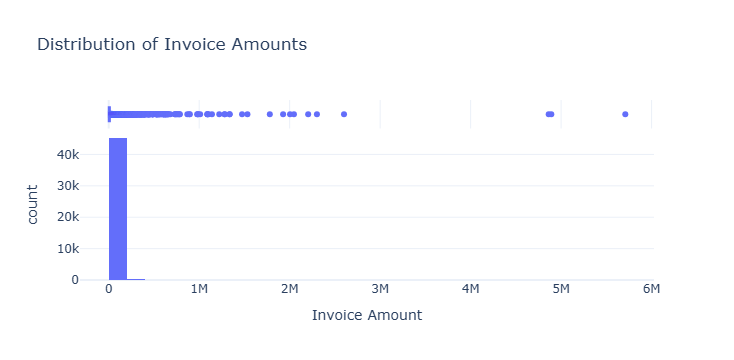

In [44]:
fig = px.histogram(
    df,
    x="amount",
    nbins=50,
    marginal="box",
    title="Distribution of Invoice Amounts",
    labels={"amount": "Invoice Amount"},
    template="plotly_white"
)
fig.show()

* The average invoice amount is approximately 17,807, while the median is 3,196.

* The distribution is positively skewed, indicating that a small number of high-value invoices      influence the average.

* Most invoices are concentrated in the lower invoice-value ranges.

* The maximum invoice amount reaches 5,709,354, highlighting the presence of exceptionally high-value transactions.

## Payment Delay Distribution

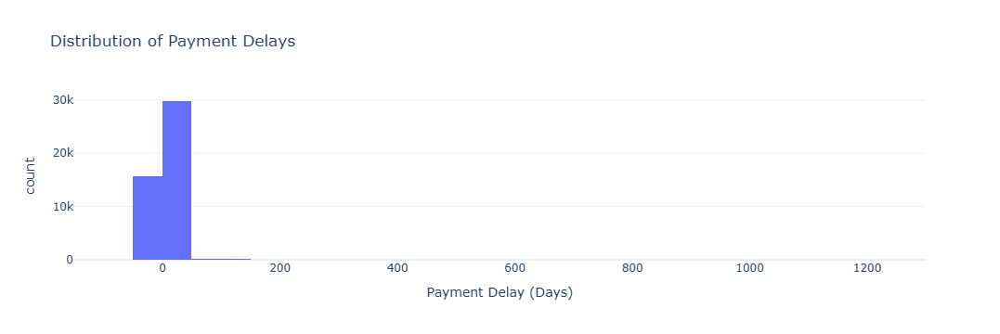

In [45]:
fig = px.histogram(
    df,
    x="days_overdue_delay",
    nbins=60,
    title="Distribution of Payment Delays",
    labels={"days_overdue_delay": "Payment Delay (Days)"},
    template="plotly_white"
)
fig.show()

* The average payment delay is approximately 1 day, with a median of 1 day.

* The minimum payment delay is -117 days, indicating that some invoices were settled before their due dates.

* The maximum recorded payment delay is 1,257 days, indicating exceptionally delayed payments.

* The distribution shows that although typical payment delays are relatively low, a small number of invoices experienced substantial delays.

* The 1–30 days delay category contains the highest number of records, with 23,477 invoices.

## Payment Status Distribution

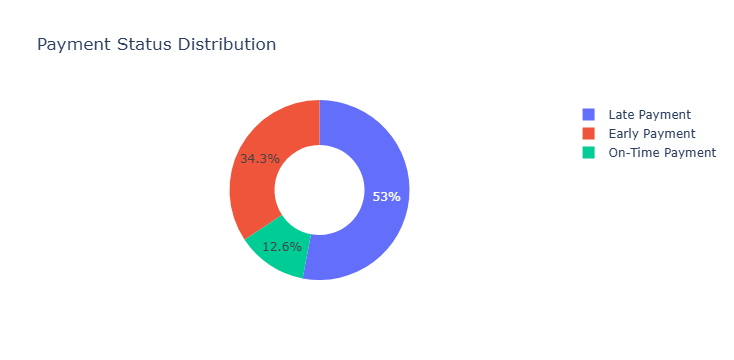

In [46]:
status = df["payment_status"].value_counts().reset_index()
status.columns = ["payment_status", "count"]

fig = px.pie(
    status,
    names="payment_status",
    values="count",
    hole=0.5,
    title="Payment Status Distribution",
    template="plotly_white"
)
fig.show()

* Late payments represent 24,299 invoices (53.01%), making them the largest category.

* Early payments account for 15,743 invoices (34.34%).

* On-time payments account for 5,797 invoices (12.65%).

* More than half of the recorded invoices were settled after their respective due dates.

* The proportion of on-time payments is comparatively low.

## Invoice Distribution by Payment Method

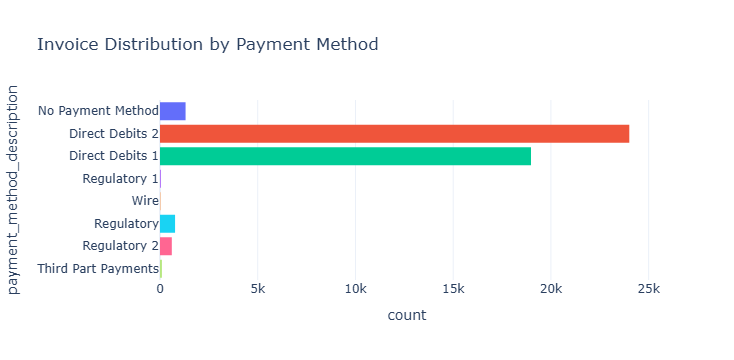

In [47]:
fig = px.histogram(
    df,
    y="payment_method_description",
    color="payment_method_description",
    title="Invoice Distribution by Payment Method",
    template="plotly_white"
)

fig.update_layout(showlegend=False)
fig.show()

* Direct Debits 2 is the most frequently used payment method, accounting for 24,010 invoices.

* Direct Debits 1 follows with 18,981 invoices.

* Together, these two categories account for approximately 93.8% of all invoice records.

* No Payment Method accounts for 1,308 invoices.

* The remaining payment methods contribute comparatively smaller invoice volumes.

## Invoice Amount vs Payment Delay

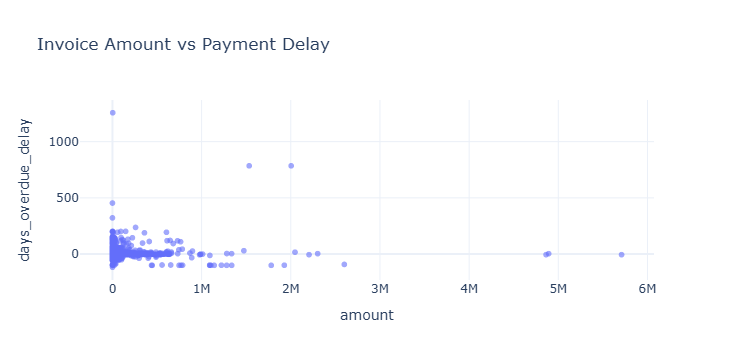

In [48]:
fig = px.scatter(
    df,
    x="amount",
    y="days_overdue_delay",
    hover_data=["cust_num", "document_no"],
    title="Invoice Amount vs Payment Delay",
    template="plotly_white",
    opacity=0.6
)
fig.show()

* The correlation between invoice amount and payment delay is approximately 0.044, indicating a very weak positive linear relationship.

* Higher invoice amounts do not consistently result in longer payment delays.

* Invoices with both low and high values are distributed across different payment-delay ranges.

* Invoice value alone does not appear to explain customer payment delays.

* Other factors, such as payment terms and customer payment behaviour, may influence payment timelines.

## Payment Terms vs Payment Cycle

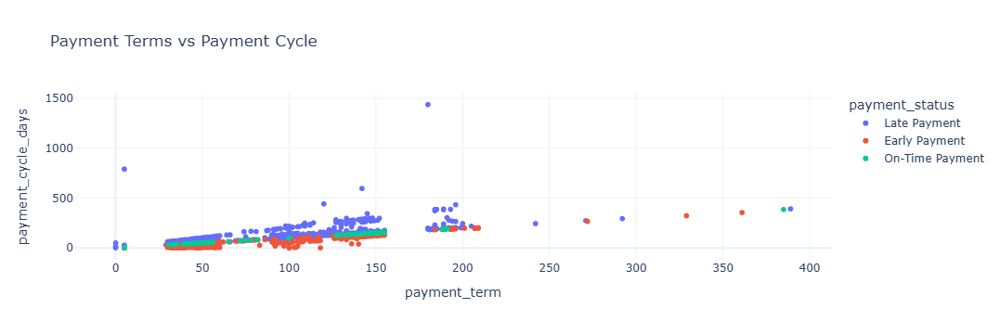

In [49]:
fig = px.scatter(
    df,
    x="payment_term",
    y="payment_cycle_days",
    color="payment_status",
    title="Payment Terms vs Payment Cycle",
    template="plotly_white",
    hover_data=["cust_num", "amount"]
)
fig.show()

* A strong positive correlation of approximately 0.891 exists between payment terms and payment cycle.

* In general, invoices with longer payment terms also tend to have longer payment cycles.

* The relationship indicates that agreed credit periods are strongly associated with actual payment timelines.

* Payment status colours provide additional information about early, on-time and late settlements.

* Some individual invoices may deviate from the overall relationship.

## Payment Status vs Invoice Amount

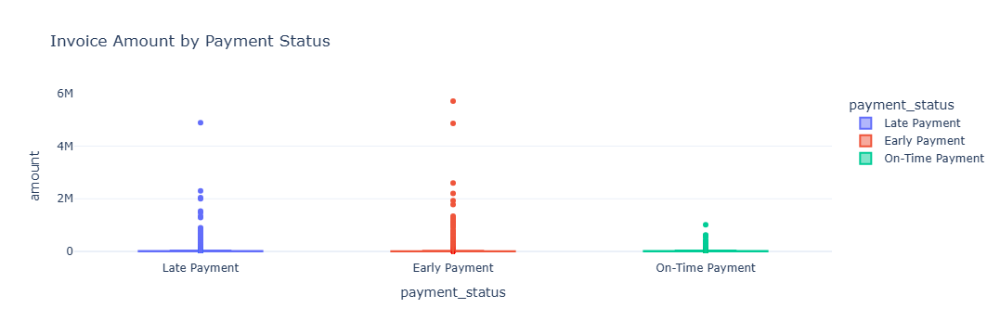

In [50]:
fig = px.box(
    df,
    x="payment_status",
    y="amount",
    color="payment_status",
    title="Invoice Amount by Payment Status",
    hover_data=["cust_num"],
    template="plotly_white"
)

fig.show()

* The median invoice amount varies across early, on-time and late payment categories.

* On-time payments have the highest median invoice amount at approximately 4,527.

* Late payments have a median invoice amount of approximately 3,196.

* Early payments have the lowest median invoice amount at approximately 2,895.

* The distributions contain high-value outliers, indicating considerable variation in invoice amounts across all payment categories.

* Invoice amount alone cannot be considered a reliable indicator of payment status.

## Payment Method vs Payment Delay

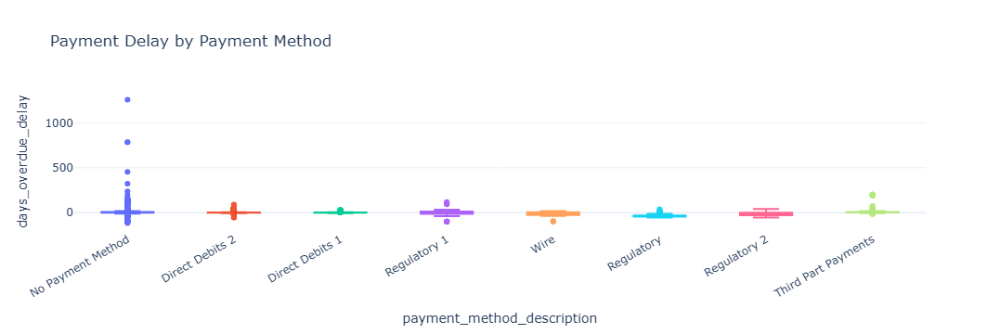

In [51]:
fig = px.box(
    df,
    x="payment_method_description",
    y="days_overdue_delay",
    color="payment_method_description",
    title="Payment Delay by Payment Method",
    template="plotly_white"
)

fig.update_layout(
    xaxis_tickangle=-30,
    showlegend=False
)

fig.show()

* Payment delays vary across the different payment methods.

* Third Part Payments and No Payment Method show comparatively higher typical payment delays.

* Regulatory demonstrates earlier payment behaviour, with a median delay of approximately -36 days.

* Direct Debits 1 has a median payment delay around the due date.

* The variation suggests that historical payment performance differs across payment methods.

* Categories with smaller invoice counts should be interpreted cautiously.

## Correlation Matrix of Key Financial Variables

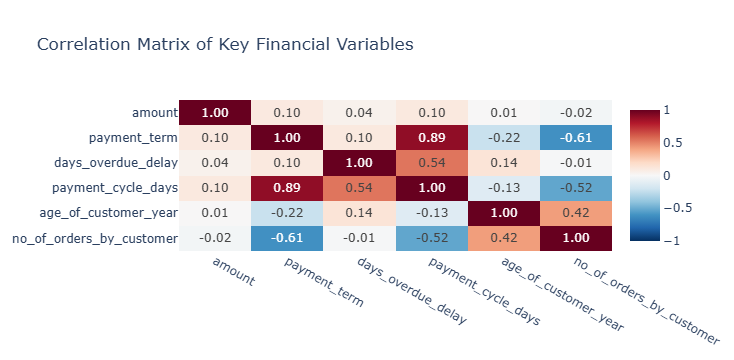

In [52]:
numeric_cols = [
    "amount",
    "payment_term",
    "days_overdue_delay",
    "payment_cycle_days",
    "age_of_customer_year",
    "no_of_orders_by_customer"
]

corr = df[numeric_cols].corr()

fig = px.imshow(
    corr,
    text_auto=".2f",
    color_continuous_scale="RdBu_r",
    zmin=-1,
    zmax=1,
    title="Correlation Matrix of Key Financial Variables",
    aspect="auto"
)

fig.update_layout(template="plotly_white")
fig.show()

* Payment terms and payment cycle show the strongest positive correlation of approximately 0.891.

* Payment delay and payment cycle have a moderate positive correlation of approximately 0.540.

* Payment terms and order count show a negative correlation of approximately -0.613.

* Payment cycle and order count also show a negative correlation of approximately -0.524.

* Invoice amount and payment delay have a very weak correlation of approximately 0.044.

* Customer age and invoice amount have almost no linear relationship, with a correlation of approximately 0.006.

* Overall, payment terms and payment cycle demonstrate the strongest association among the selected numerical variables.

## Payment Terms, Payment Cycle and Invoice Amount

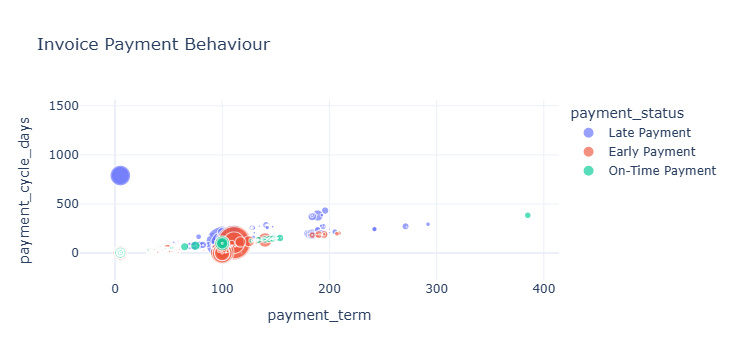

In [53]:
fig = px.scatter(
    df,
    x="payment_term",
    y="payment_cycle_days",
    size="amount",
    color="payment_status",
    hover_data=[
        "cust_num",
        "document_no",
        "amount",
        "days_overdue_delay"
    ],
    title="Invoice Payment Behaviour",
    size_max=35,
    opacity=0.65,
    template="plotly_white"
)

fig.show()

* The visualization combines payment terms, payment cycle, invoice amount and payment status.

* A positive relationship can be observed between payment terms and payment cycle.

* Bubble sizes represent invoice amounts, helping identify high-value transactions.

* Different colours distinguish early, on-time and late payment categories.

* The visualization provides a combined view of invoice value and payment behaviour across different payment terms.

* It helps identify individual high-value invoices and their corresponding payment patterns.

In [54]:
correlation = df["payment_term"].corr(df["payment_cycle_days"])

print("Correlation:", round(correlation, 3))

Correlation: 0.891


## Interpretation of Payment Terms and Payment Cycle

The correlation coefficient between Payment Terms and Payment Cycle Days is approximately 0.891, indicating a strong positive linear relationship.

This suggests that invoices with longer agreed payment terms generally tend to have longer payment cycles. Therefore, payment terms are an important variable when analysing historical customer payment behaviour.

However, correlation does not necessarily indicate causation.

## Payment Status Composition by Payment Method

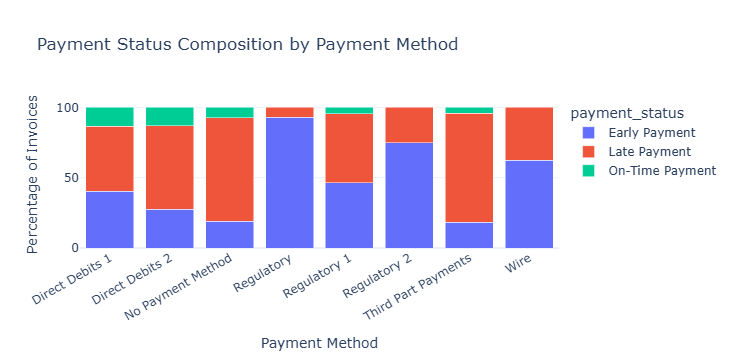

In [55]:
method_status = (
    df.groupby([
        "payment_method_description",
        "payment_status"
    ])
    .size()
    .reset_index(name="invoice_count")
)

method_status["percentage"] = (
    method_status.groupby("payment_method_description")[
        "invoice_count"
    ].transform(lambda x: x / x.sum() * 100)
)

fig = px.bar(
    method_status,
    x="payment_method_description",
    y="percentage",
    color="payment_status",
    barmode="stack",
    hover_data=["invoice_count"],
    title="Payment Status Composition by Payment Method",
    labels={
        "percentage": "Invoice Percentage (%)",
        "payment_method_description": "Payment Method"
    },
    template="plotly_white"
)

fig.update_layout(
    yaxis_title="Percentage of Invoices",
    xaxis_tickangle=-30
)

fig.show()

* Third Part Payments has the highest late-payment rate at 77.55%.

* No Payment Method follows with a late-payment rate of 73.62%.

* Direct Debits 2 records a late-payment rate of 59.20%.

* Direct Debits 1 records a late-payment rate of 46.42%.

* Regulatory 2 has a late-payment rate of 25.17%.

* Regulatory demonstrates the lowest late-payment rate at 7.00%.

* The findings indicate considerable differences in historical payment performance across payment methods.

* Smaller payment-method categories require cautious interpretation due to limited invoice counts.

## Customer Payment Risk Analysis

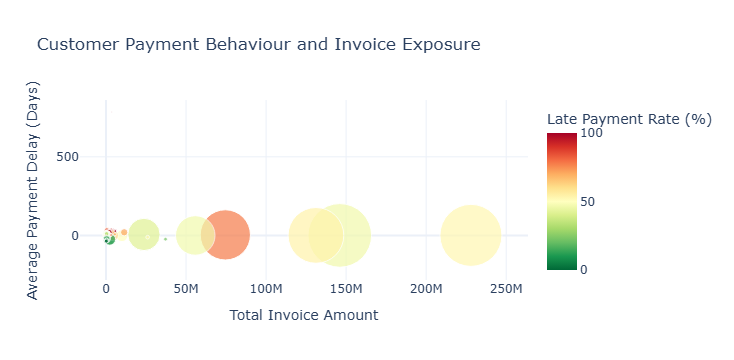

In [56]:
fig = px.scatter(
    customer_df,
    x="total_invoice_amount",
    y="average_delay",
    size="total_invoices",
    color="late_payment_rate",
    hover_name="cust_num",
    hover_data=[
        "total_invoices",
        "late_payments",
        "maximum_delay"
    ],
    color_continuous_scale="RdYlGn_r",
    size_max=45,
    title="Customer Payment Behaviour and Invoice Exposure",
    labels={
        "total_invoice_amount": "Total Invoice Amount",
        "average_delay": "Average Payment Delay (Days)",
        "total_invoices": "Total Invoices",
        "late_payment_rate": "Late Payment Rate (%)"
    },
    template="plotly_white"
)

fig.show()

* The analysis covers 69 unique customers.

* Customer 5039221094 has the highest total invoice amount of 227,964,488, across 9,712 invoices.

* Customer 5039221090 has the highest invoice count, with 10,219 invoices and a total invoice amount of 146,033,618.

* Customer 5039221093 records a late-payment rate of 77.73%, with an average payment delay of 3.60 days.

* Customer 5039221097 has the highest average payment delay among these highlighted customers, at 20.13 days, with a late-payment rate of 71.11%.

* Customer 5039221071 has an average payment delay of -23.58 days, indicating early payment behaviour on average.

* The visualization helps identify customers with significant historical invoice exposure and comparatively higher late-payment rates.

## Conclusion

The Exploratory Data Analysis provided valuable insights into historical accounts receivable performance, invoice payment patterns, customer behaviour and the relationships between important financial variables.

The analysis of 45,839 invoice records across 69 unique customers revealed several significant findings.

1. Invoice and Payment Behaviour

Invoice amounts showed a positively skewed distribution, with an average invoice value of approximately 17,807.16 compared with a median of 3,196. This indicates that most invoices are concentrated in lower-value ranges, while a relatively small number of high-value invoices influence the average.

The payment delay analysis showed an average delay of approximately 0.97 days and a median of 1 day. However, the maximum recorded delay of 1,257 days highlights the presence of exceptionally delayed historical payments.

Payment status analysis revealed that 53.01% of invoices were paid late, while 34.34% were paid early and 12.65% were paid on time. This indicates that late payments represent the largest category in the dataset.

Direct Debits 1 and Direct Debits 2 together account for approximately 93.8% of all invoice records, demonstrating the significant concentration of invoice transactions within these two payment methods.

2. Relationships Between Financial Variables

A strong positive correlation of approximately 0.891 was identified between payment terms and payment cycle days. This indicates that invoices with longer agreed payment terms generally tend to have longer payment cycles.

Payment delay and payment cycle days showed a moderate positive correlation of approximately 0.540.

Invoice amount and payment delay showed a very weak positive correlation of approximately 0.044, suggesting that invoice value alone does not strongly explain payment delays.

The analysis of invoice amounts across payment statuses showed differences in median invoice values, but high-value transactions appeared across all payment categories.

These findings highlight the importance of considering multiple financial and customer-related variables rather than relying on invoice amount alone to understand payment behaviour.

3. Payment Method Analysis

The analysis identified considerable differences in historical late-payment rates across payment methods.

Third Part Payments recorded the highest late-payment rate at 77.55%, followed by No Payment Method at 73.62% and Direct Debits 2 at 59.20%. Regulatory recorded the lowest late-payment rate at 7.00%.

These variations indicate that historical payment performance differs across payment methods. However, categories with smaller invoice volumes should be interpreted cautiously.

4. Customer-Level Analysis

The customer-level analysis highlighted differences in historical invoice exposure, transaction volumes and payment behaviour.

Customer 5039221094 recorded the highest total invoice amount of approximately 227.96 million, while Customer 5039221090 recorded the highest invoice volume with 10,219 invoices.

The analysis also identified customers with comparatively higher late-payment rates and longer average payment delays, while some customers demonstrated early payment behaviour.

This analysis provides a useful basis for understanding historical customer payment patterns and identifying areas that may require further investigation.

5. Overall Outcome

Overall, the EDA identified late payments as a significant pattern in the historical receivables data. The strong relationship between payment terms and payment cycle, variations in payment performance across payment methods, and differences in customer-level payment behaviour provide important insights into the factors associated with invoice settlement timelines.